<a href="https://colab.research.google.com/github/tettehdaniel/python-labs/blob/main/Notebooks/Notebook14_StatInference2_SV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 14 — Statistical Inference Two

**Main Objective**

1. Independent Samples (Two-Sample) t-Test
2. One-Way (Between Subjects) ANOVA
3. Chi-Squared Test (of Independence)

## Setup

Please run the setup code below

In [1]:
! wget -q -nc https://raw.githubusercontent.com/taylor-arnold/fds-py/refs/heads/main/funs.py

from funs import *

In [2]:
import numpy as np
import polars as pl

from plotnine import *
from polars import col as c
theme_set(theme_minimal())

path = "https://raw.githubusercontent.com/ajcollins16/DSST289_Fall2026_AJC/refs/heads/main/"

In [3]:
sales = pl.read_csv(path + "Data/SupermarketSales.csv")

## Mean Comparisons

The Supermart Grocery Sales dataset contains transaction-level information from a fictional grocery retail company. Each row represents an individual customer order and includes information about the product that was purchased, where the purchase occurred, and the financial outcome of the transaction. Important variables include the product `Category` and `Sub_Category`, the customer's `City` and `Region` (all around in the country of India), and numerical measures such as `Sales`, `Discount`, and `Profit`.

We are going to break up the questions below into three main parts, one for each of the analyses we are going over: the independent samples t-test, the one-way (between subjects) ANOVA, and the chi-squared test of independence.

### Questions (Set One: Indpendent Samples t-Test)

For our first analysis, we are interested in whether the average amount spent on an order differs between customers in the East and West regions.

1. Filter the supermarket dataset so that it contains only observations from the "East" and "West" `Region`s, and then create a boxplot that displays `Sales` separately for these two regions.

In [4]:
sales.head(1)

Category,Sub_Category,City,Region,Sales,Discount,Profit
str,str,str,str,i64,f64,f64
"""Oil & Masala""","""Masalas""","""Vellore""","""North""",1254,0.12,401.28


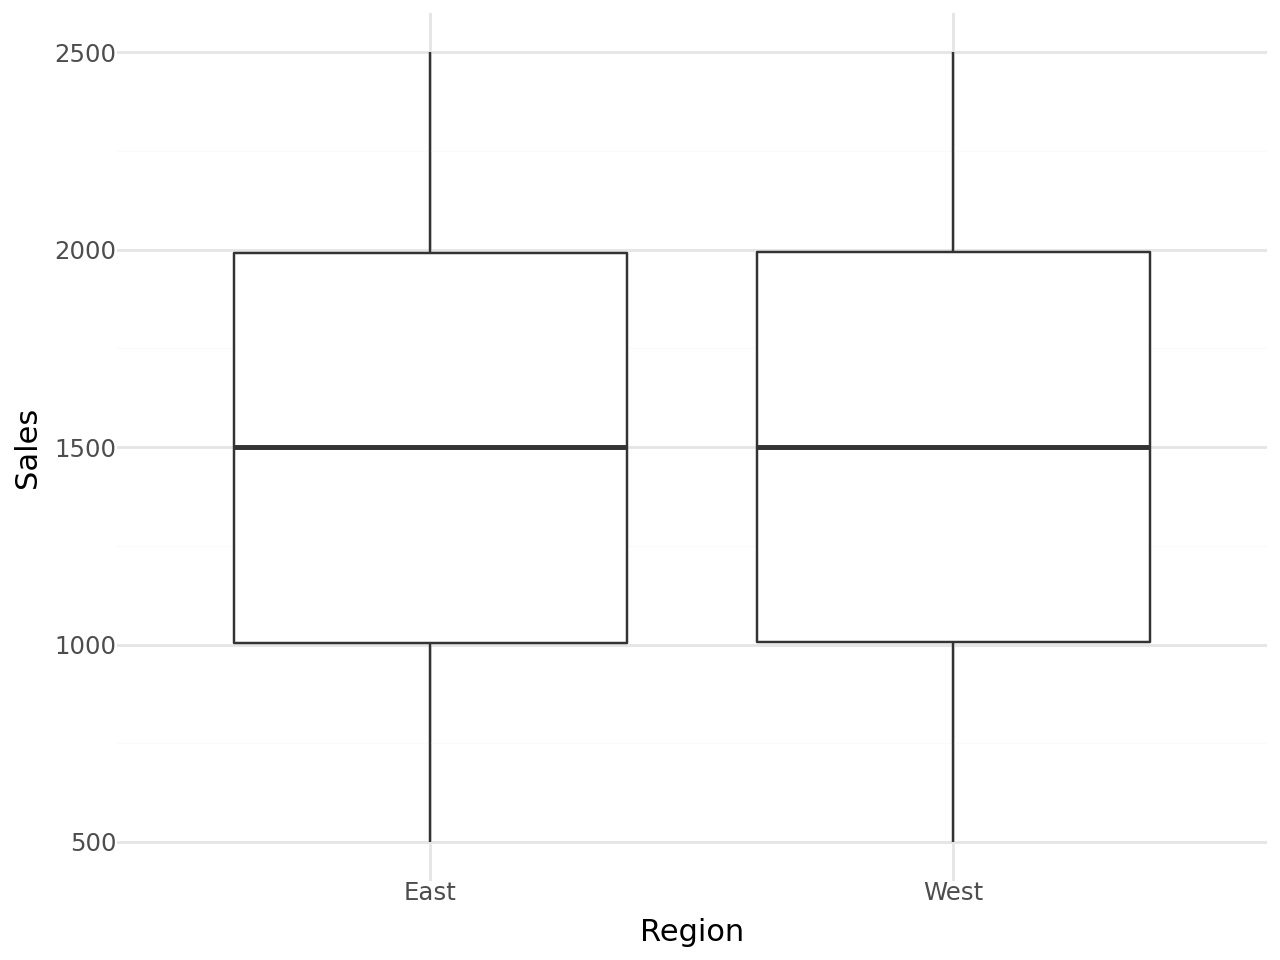

In [5]:
(
    sales
    .filter(c.Region.is_in(["West", "East"]))
    .pipe(ggplot, aes("Region", "Sales"))
    + geom_boxplot()
)

1. Based on the visualization above, do you expect average sales to differ between the East and West regions?

**Answer (Q1):** No

2. Before running our statistical test, what would the null hypothesis ($H_0$) and alternative hypothesis ($H_1$) be for comparing average sales between the East and West regions?

**Answer (Q2):** The average sales between the East and West regions are equal

3. Run an independent samples t-test comparing `Sales` between the "East" and "West" `Region`s. Make sure you filter the data first to only include these two regions before you run the analysis.

In [6]:
(
    sales
    .filter(c.Region.is_in(["East", "West"]))
    .pipe(DSStatsmodels.ttest2, "Sales ~ Region")
)

level1,level2,mean1,mean2,mean_diff,t,P>|t|,[0.025,0.975]
str,str,f64,f64,f64,f64,f64,f64,f64
"""East""","""West""",1491.702247,1498.202623,6.500375,0.437132,0.662031,-22.651129,35.65188


3. Using the output from the independent samples t-test above, answer the following questions:

- **First.** What is the p-value from the statistical test? **Answer:** 0.66

- **Second.** Using $\alpha = .05$, would you reject or fail to reject the null hypothesis? **Answer:** Fail to reject the null hypothesis

- **Third.** What does the p-value tell us about the evidence for a difference in average sales between the East and West regions? **Answer:** No evidence for statistically significant

- **Fourth:** What is the 95% confidence interval for the difference in average sales between the East and West regions? **Answer:** (0.025, 0.975)

- **Fifth:** In the context of this supermarket, what is your overall conclusion about average sales in the East and West regions? **Answer:** The average sales in the two regions are likely equal

### Questions (Set Two: One-Way ANOVA)

Next, we will expand our comparison beyond two regions and determine whether average sales differ among the Central, East, South, and West regions.

1. Remove observations from the "North" `Region` and then create a boxplot that displays `Sales` separately for the "Central", "East", "South", and "West" `Regions`.

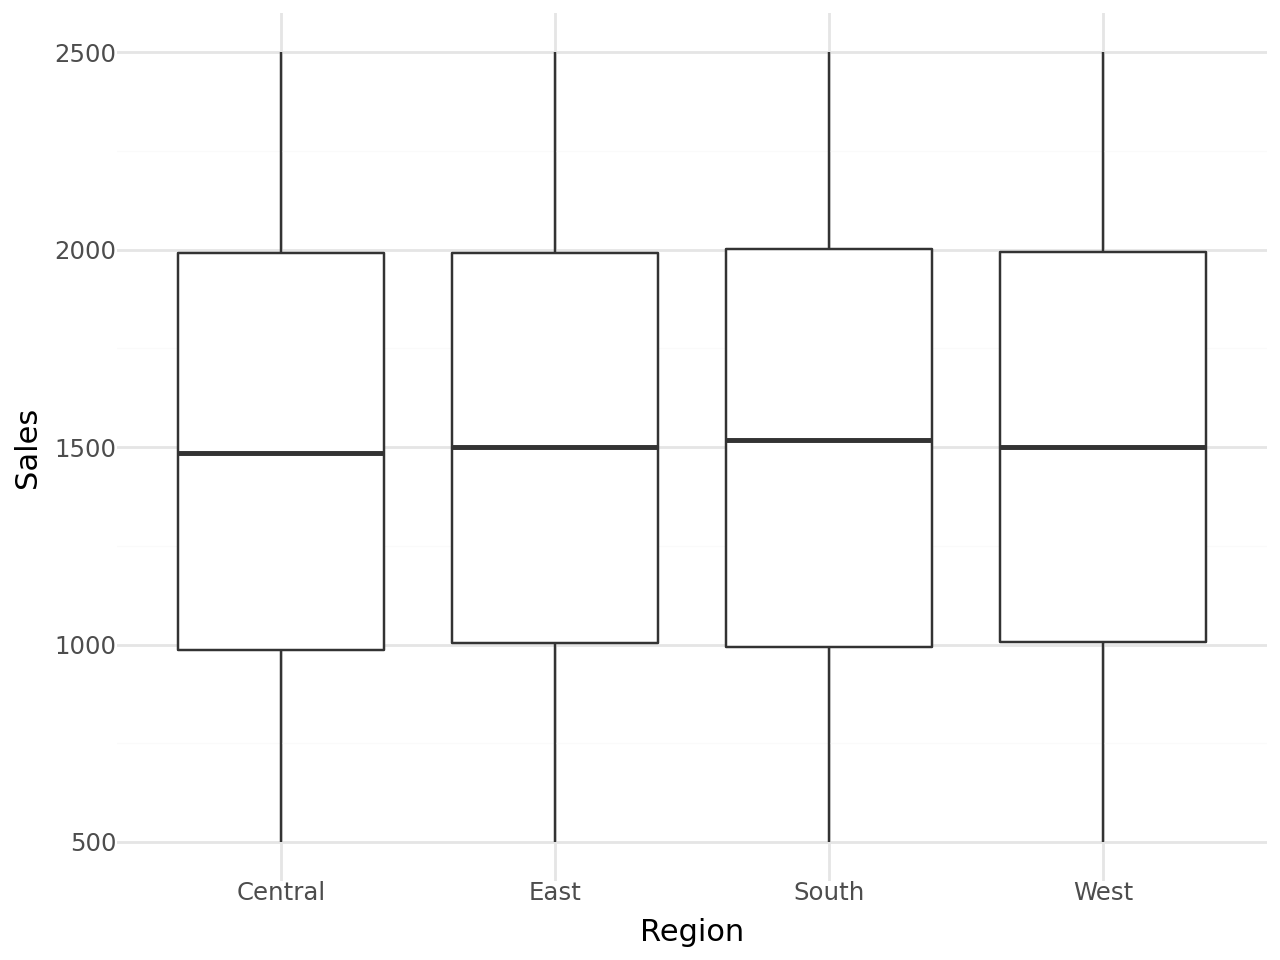

In [7]:
(
    sales
    .filter(c.Region.is_in(["Central", "East", "South", "West"]))
    .pipe(ggplot, aes("Region", "Sales"))
    + geom_boxplot()
)

1. Based on the visualization above, do any of the regions appear to have noticeably different average sales from the others?

**Answer (Q1):**  No

2. Before running our statistical test, what would the null hypothesis ($H_0$) and alternative hypothesis ($H_1$) be for comparing average sales across the four regions?

**Answer (Q2):** Null hypothesis is that all regions means are equal, Alt hypothesis is there's at least one region mean different from the others.

3. Run a one-way between-subjects ANOVA comparing `Sales` across `Region` making sure to filter out the north region before running the analysis (like in Q1 above).

In [8]:
(
    sales
    .filter(c.Region.is_in(["Central", "West", "South", "East"]))
    .pipe(DSStatsmodels.anova, "Sales ~ Region")
)

index,sum_sq,df,F,PR(>F)
str,f64,f64,f64,f64
"""Region""",295663.866571,3.0,0.295363,0.828782
"""Residual""",3.3331e9,9989.0,null,null


3. Using the output from the one-way ANOVA above, answer the following questions:

- **First.** What is the p-value from the statistical test? **Answer:** 0.83

- **Second.** Using $\alpha = .05$, would you reject or fail to reject the null hypothesis? **Answer:** Fail to reject the null hypothesis

- **Third.** What does the p-value tell us about the evidence for differences in average sales among the four regions? **Answer:** No evidence for statistically significant

- **Fourth:** Based on the ANOVA, what can we conclude about the population means for the Central, East, South, and West regions? **Answer:** We can conclude that there's no difference in means for the four regions.

- **Fifth:** If the ANOVA is statistically significant, does the ANOVA by itself tell us which specific regions differ from one another? **Answer:**

### Question (Set Three: Chi-Squared Test of Independence)

For our final analysis, we will move away from comparing a quantitative outcome and instead investigate the relationship between two categorical variables: the geographic Region of an order and its product Category.

1. Remove observations from the "North" `Region` and then create a bar plot that displays the distribution of each `Category` separately (via `fill`) for the "Central", "East", "South", and "West" `Region`s. When using the `geom_col()` function set `position = "dodge"`.

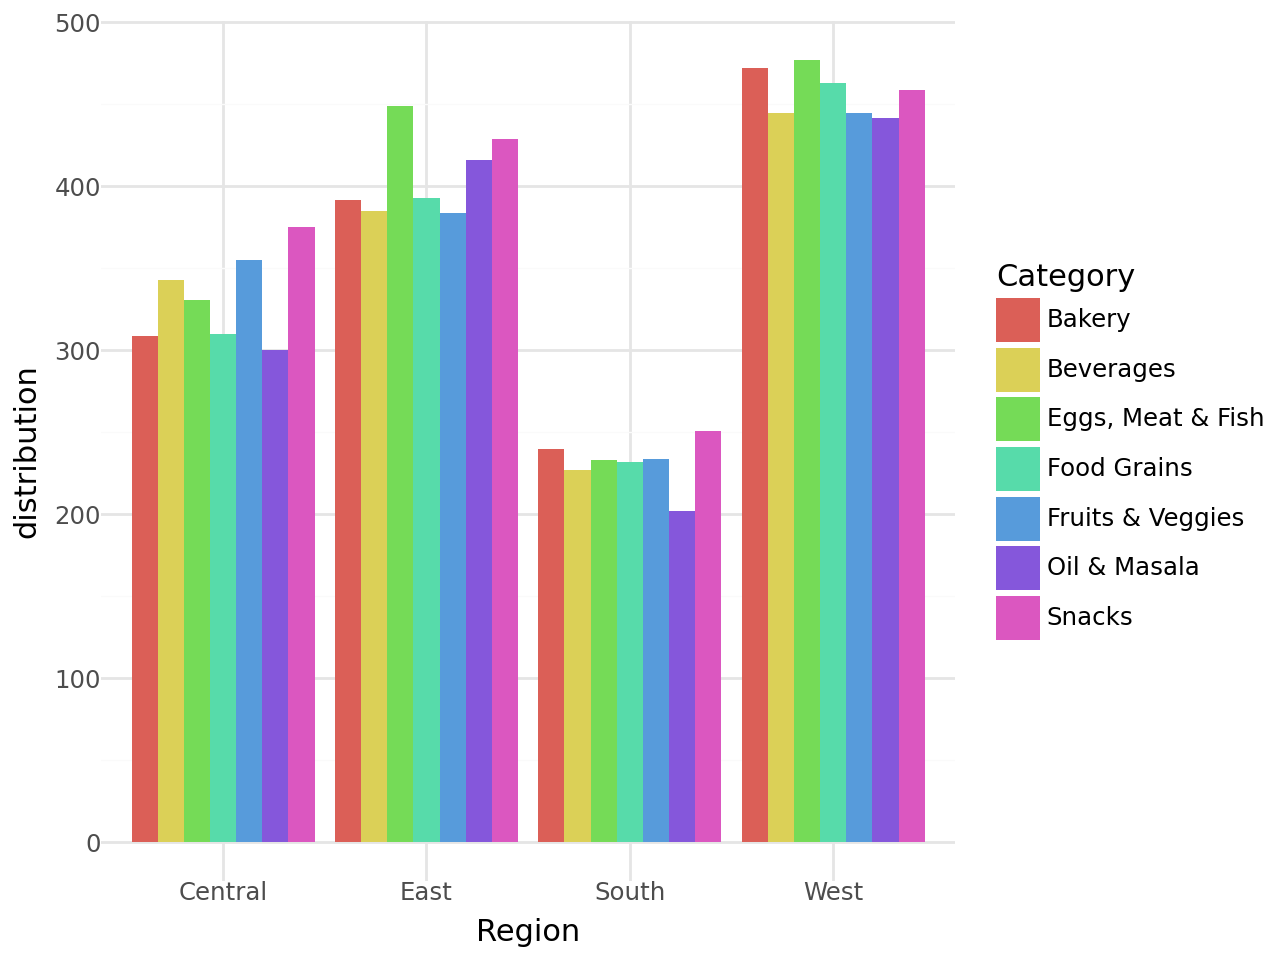

In [9]:
(
    sales
    .filter(c.Region.is_in(["Central", "South", "West", "East"]))
    .group_by(c.Region, c.Category)
    .agg(
        distribution = pl.len()
    )
    .pipe(ggplot, aes("Region", "distribution"))
    + geom_col(aes(fill = "Category"), position = "dodge")
)

1. Based on the visualization above, does the distribution of product categories appear to differ depending on the region?

**Answer (Q1):** Yes

2. Before running our statistical test, what would the null hypothesis ($H_0$) and alternative hypothesis ($H_1$) be when testing whether Region and Category are independent of one another?

**Answer (Q2):**

3. Create a (contingency) table containing the observed counts for `Region` and `Category`, making sure to filter out the north again.

In [10]:
sales.head(1)

Category,Sub_Category,City,Region,Sales,Discount,Profit
str,str,str,str,i64,f64,f64
"""Oil & Masala""","""Masalas""","""Vellore""","""North""",1254,0.12,401.28


In [11]:
(
    sales
    .filter(c.Region.is_in(["Central", "South", "West", "East"]))
    .group_by(c.Region, c.Category)
    .agg(
        distribution = pl.len()
    )
    .pivot(index = "Region", on = "Category", values = "distribution" )
)

Region,Beverages,Food Grains,Bakery,"Eggs, Meat & Fish",Snacks,Oil & Masala,Fruits & Veggies
str,u32,u32,u32,u32,u32,u32,u32
"""South""",227,232,240,233,251,202,234
"""West""",445,463,472,477,459,442,445
"""Central""",343,310,309,331,375,300,355
"""East""",385,393,392,449,429,416,384


4. Run a chi-squared test of independence examining the relationship between `Region` and `Category`.

In [12]:
(
    sales
    .pipe(DSStatsmodels.chi2, "Region ~ Category")
)

χ²,df,P>|χ²|
f64,i64,f64
25.186625,24,0.395677


4. Using the output from the chi-squared test above, answer the following questions:

- **First.** What is the p-value from the statistical test? **Answer:** 0.39

- **Second.** Using $\alpha = .05$, would you reject or fail to reject the null hypothesis? **Answer:** Fail to reject null hypothesis

- **Third.** What does the p-value tell us about the evidence for an association between region and the type of product purchased? **Answer:** There is not statistical significance

- **Fourth:** In the context of this supermarket, what would it mean for Region and Category to be independent? **Answer:** They are dependent of each other

- **Fifth:** Based on the statistical test, what is your overall conclusion about the relationship between geographic region and product category? **Answer:** Product category